In [1]:
# multimodal_price_regressor.py
import os, math, random, time
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sentence_transformers import SentenceTransformer
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from PIL import Image
from torchvision import transforms
import clip  # pip install git+https://github.com/openai/CLIP.git
from tqdm import tqdm

device = "cuda:1" if torch.cuda.is_available() else "cpu"
embeddings_folder = 'embeddings'
os.makedirs(embeddings_folder, exist_ok=True)

In [2]:
# -------------------------
# Utility: SMAPE metric
# -------------------------
def smape(y_true, y_pred, eps=1e-8):
    num = np.abs(y_pred - y_true)
    den = (np.abs(y_true) + np.abs(y_pred)) / 2.0 + eps
    return np.mean(num / den)

def smape_torch(y_true, y_pred, eps=1e-8):
    num = (y_pred - y_true).abs()
    den = (y_true.abs() + y_pred.abs()) / 2 + eps
    return (num / den).mean()

In [3]:
# -------------------------
# 1) Load CSV and create stratified val
# -------------------------
df = pd.read_csv('../clean_data/train_cleaned.csv')  # adjust path
df["Description"] = df["Description"].fillna("")
df["Item Name"] = df["Item Name"].fillna("")
df["Unit"] = df["Unit"].fillna("unknown")
df["Value"] = df["Value"].fillna(1.0)
df["price"] = df["price"].astype(float)



# # Quick preprocessing: fill nans
# df['catalog_content'] = df['catalog_content'].fillna('')

# create log price bins for stratified split
df['log_price'] = np.log1p(df['price'])
df['price_bin'] = pd.qcut(df['log_price'], 10, labels=False, duplicates='drop')

train_df, val_df = train_test_split(df, test_size=0.1, random_state=42, stratify=df['price_bin'])
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)

print(f"Train: {len(train_df)}, Val: {len(val_df)}")

Train: 67499, Val: 7500


## Load Embeddings

In [7]:
# load all the data
train_text_emb = np.load(os.path.join(embeddings_folder, 'train_text_emb.npy'))
val_text_emb = np.load(os.path.join(embeddings_folder, 'val_text_emb.npy'))
train_img_emb = np.load(os.path.join(embeddings_folder, 'train_img_emb.npy'))
val_img_emb = np.load(os.path.join(embeddings_folder, 'val_img_emb.npy'))
train_num_scaled = np.load(os.path.join(embeddings_folder, 'train_num_scaled.npy'))
val_num_scaled = np.load(os.path.join(embeddings_folder, 'val_num_scaled.npy'))

In [8]:
clip_model, clip_preprocess = clip.load("ViT-B/32", device=device, jit=False)  # ViT-B/32 is compact

In [9]:
# -------------------------
# 5) Dataset + DataLoader
# -------------------------
class MultimodalDataset(Dataset):
    def __init__(self, text_embs, img_embs, num_feats, prices):
        self.text = text_embs.astype(np.float32)
        self.img = img_embs.astype(np.float32)
        self.num = num_feats.astype(np.float32)
        self.y = prices.astype(np.float32)
    def __len__(self):
        return len(self.y)
    def __getitem__(self, idx):
        return {'text': self.text[idx], 'img': self.img[idx], 'num': self.num[idx], 'y': self.y[idx]}

train_ds = MultimodalDataset(train_text_emb, train_img_emb, train_num_scaled, np.log1p(train_df['price'].values))
val_ds = MultimodalDataset(val_text_emb, val_img_emb, val_num_scaled, np.log1p(val_df['price'].values))

train_loader = DataLoader(train_ds, batch_size=1000, shuffle=True, num_workers=4)
val_loader = DataLoader(val_ds, batch_size=1000, shuffle=False, num_workers=2)

NameError: name 'train_df' is not defined

In [10]:
# -------------------------
# 6) Fusion model (simple MLP)
# -------------------------
import torch
import torch.nn as nn

class ResidualBlockMLP(nn.Module):
    def __init__(self, dim, hidden_dim=None, dropout=0.2):
        """
        A residual block: input x → FC → ReLU → Dropout → FC → addition with x
        If hidden_dim is None, use dim internally.
        """
        super().__init__()
        hidden_dim = hidden_dim or dim
        self.fc1 = nn.Linear(dim, hidden_dim)
        self.act = nn.ReLU()
        self.dropout = nn.Dropout(dropout)
        self.fc2 = nn.Linear(hidden_dim, dim)
        # Optionally, layernorm to stabilize
        self.norm = nn.LayerNorm(dim)

    def forward(self, x):
        # x: (batch_size, dim)
        residual = x
        out = self.fc1(x)
        out = self.act(out)
        out = self.dropout(out)
        out = self.fc2(out)
        out = self.dropout(out)
        # add skip
        out = out + residual
        out = self.norm(out)
        return out

class FusionResidualMLP(nn.Module):
    def __init__(self, text_dim, img_dim, num_dim, 
                 hidden_dim=2048, n_blocks=3, dropout=0.2):
        super().__init__()
        # initial linear to project into a joint hidden space
        total_dim = text_dim + img_dim + num_dim
        self.proj = nn.Linear(total_dim, hidden_dim)
        self.act = nn.ReLU()
        self.dropout = nn.Dropout(dropout)

        # residual blocks
        self.blocks = nn.ModuleList([
            ResidualBlockMLP(hidden_dim, hidden_dim, dropout=dropout)
            for _ in range(n_blocks)
        ])

        # final reg head
        self.head = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim // 2),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim // 2, 1)
        )

    def forward(self, text, img, num):
        x = torch.cat([text, img, num], dim=1)
        x = self.proj(x)
        x = self.act(x)
        x = self.dropout(x)
        for blk in self.blocks:
            x = blk(x)
        out = self.head(x).squeeze(1)
        return out


# detect image dimension from clip model:
img_dim = clip_model.visual.output_dim
model = FusionResidualMLP(text_dim=train_text_emb.shape[1], img_dim=img_dim, num_dim=train_num_scaled.shape[1], hidden_dim=1024)
model = model.to(device)

# # print model summary
# from torchsummary import summary
# summary(model, [(train_text_emb.shape[1],), (img_dim,), (train_num_scaled.shape[1],)], device=device)

In [8]:
# -------------------------
# 7) Training loop (MAE loss on log price), report SMAPE
# -------------------------
optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-5)
criterion = nn.L1Loss()  # MAE on log price
epochs = 800

plot_train_losses = []
plot_val_losses = []
plot_val_smapes = []

for epoch in range(epochs):
    model.train()
    train_losses = []
    for batch in train_loader:
        text = torch.tensor(batch['text']).to(device)
        img = torch.tensor(batch['img']).to(device)
        num = torch.tensor(batch['num']).to(device)
        y = torch.tensor(batch['y']).to(device)
        preds = model(text, img, num)
        loss = criterion(preds, y)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        train_losses.append(loss.item())
    # validation
    model.eval()
    ys = []
    yps = []
    val_losses = []
    with torch.no_grad():
        for batch in val_loader:
            text = torch.tensor(batch['text']).to(device)
            img = torch.tensor(batch['img']).to(device)
            num = torch.tensor(batch['num']).to(device)
            y = torch.tensor(batch['y']).to(device)
            pred = model(text, img, num)
            loss = criterion(pred, y)
            ys.append(y.cpu().numpy())
            yps.append(pred.cpu().numpy())
            val_losses.append(loss.item())
    ys = np.concatenate(ys)
    yps = np.concatenate(yps)
    # convert back from log1p
    y_true = np.expm1(ys)
    y_pred = np.expm1(yps)
    val_smape = smape(y_true, y_pred)
    plot_train_losses.append(np.mean(train_losses))
    plot_val_losses.append(np.mean(val_losses))
    plot_val_smapes.append(val_smape)
    if (epoch+1) % 10 == 0 or epoch == 0:
        print(f"Epoch {epoch+1}/{epochs} train_loss={np.mean(train_losses):.4f} val_loss={np.mean(val_losses):.4f} val_smape={val_smape:.4f}")
    if (epoch+1) % 20 == 0:
        os.makedirs('models', exist_ok=True)
        torch.save(model.state_dict(), f'models/model_epoch{epoch+1}.pth')


/tmp/ipykernel_2169524/1952969063.py:16: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  text = torch.tensor(batch['text']).to(device)
/tmp/ipykernel_2169524/1952969063.py:17: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  img = torch.tensor(batch['img']).to(device)
/tmp/ipykernel_2169524/1952969063.py:18: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  num = torch.tensor(batch['num']).to(device)
/tmp/ipykernel_2169524/1952969063.py:19: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sour

Epoch 1/800 train_loss=0.7038 val_loss=0.6368 val_smape=0.6219


/tmp/ipykernel_2169524/1952969063.py:33: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  text = torch.tensor(batch['text']).to(device)
/tmp/ipykernel_2169524/1952969063.py:34: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  img = torch.tensor(batch['img']).to(device)
/tmp/ipykernel_2169524/1952969063.py:35: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  num = torch.tensor(batch['num']).to(device)
/tmp/ipykernel_2169524/1952969063.py:36: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sour

Epoch 10/800 train_loss=0.4281 val_loss=0.5764 val_smape=0.5652
Epoch 20/800 train_loss=0.3174 val_loss=0.5456 val_smape=0.5353
Epoch 30/800 train_loss=0.2632 val_loss=0.5848 val_smape=0.5670
Epoch 40/800 train_loss=0.2288 val_loss=0.5830 val_smape=0.5655
Epoch 50/800 train_loss=0.2066 val_loss=0.5456 val_smape=0.5329
Epoch 60/800 train_loss=0.1913 val_loss=0.5852 val_smape=0.5636
Epoch 70/800 train_loss=0.1798 val_loss=0.5376 val_smape=0.5246
Epoch 80/800 train_loss=0.1711 val_loss=0.5551 val_smape=0.5366
Epoch 90/800 train_loss=0.1641 val_loss=0.5570 val_smape=0.5390
Epoch 100/800 train_loss=0.1598 val_loss=0.5409 val_smape=0.5256
Epoch 110/800 train_loss=0.1535 val_loss=0.5561 val_smape=0.5383
Epoch 120/800 train_loss=0.1473 val_loss=0.5421 val_smape=0.5245
Epoch 130/800 train_loss=0.1461 val_loss=0.5608 val_smape=0.5402
Epoch 140/800 train_loss=0.1382 val_loss=0.5554 val_smape=0.5356
Epoch 150/800 train_loss=0.1396 val_loss=0.5255 val_smape=0.5110
Epoch 160/800 train_loss=0.1329 va

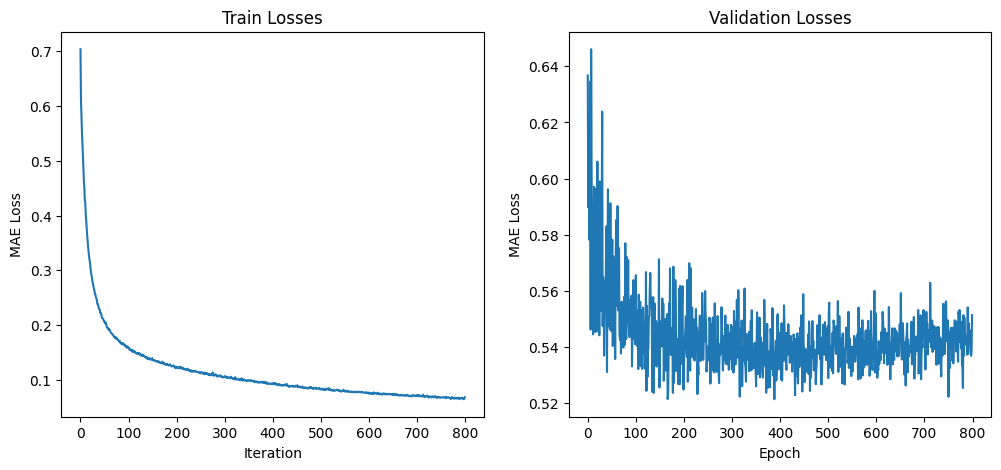

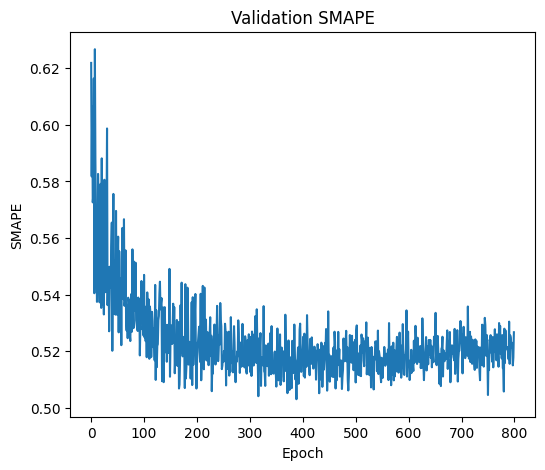

In [9]:
# plot training curves
import matplotlib.pyplot as plt
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(plot_train_losses)
plt.title('Train Losses')
plt.xlabel('Iteration')
plt.ylabel('MAE Loss')
plt.subplot(1,2,2)
plt.plot(plot_val_losses)
plt.title('Validation Losses')
plt.xlabel('Epoch')
plt.ylabel('MAE Loss')
plt.show()

plt.figure(figsize=(6,5))
plt.plot(plot_val_smapes)
plt.title('Validation SMAPE')
plt.xlabel('Epoch')
plt.ylabel('SMAPE')
plt.show()

In [12]:
# load model for test set inference
model.load_state_dict(torch.load(f'models/model_epoch380.pth', map_location=device))

model.eval()
# -------------------------
# 8) Inference on test set
# -------------------------
test_df = pd.read_csv('../clean_data/test_cleaned.csv')  # adjust path
test_df["Description"] = test_df["Description"].fillna("")
test_df["Item Name"] = test_df["Item Name"].fillna("")
test_df["Unit"] = test_df["Unit"].fillna("unknown")
test_df["Value"] = test_df["Value"].fillna(1.0)
test_df['log_price'] = 0.0  # dummy
test_df['price_bin'] = 0  # dummy
test_df = test_df.reset_index(drop=True)

test_text_emb = np.load(os.path.join(embeddings_folder, 'test_text_emb.npy'))
test_img_emb = np.load(os.path.join(embeddings_folder, 'test_img_emb.npy'))
test_num_scaled = np.load(os.path.join(embeddings_folder, 'test_num_scaled.npy'))
test_ds = MultimodalDataset(test_text_emb, test_img_emb, test_num_scaled, np.log1p(test_df['log_price'].values))
test_loader = DataLoader(test_ds, batch_size=1000, shuffle=False, num_workers=2)

preds = []
with torch.no_grad():
    for batch in test_loader:
        text = torch.tensor(batch['text']).to(device)
        img = torch.tensor(batch['img']).to(device)
        num = torch.tensor(batch['num']).to(device)
        pred = model(text, img, num)
        preds.append(pred.cpu().numpy())
preds = np.concatenate(preds)
preds = np.expm1(preds)  # convert back from log1p
submission_df = pd.DataFrame({'sample_id': test_df['sample_id'], 'price': preds})
submission_df.to_csv('submission_residual.csv', index=False)
# -----------------------------------------
# End of file
# -----------------------------------------

/tmp/ipykernel_2252945/3677355926.py:26: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  text = torch.tensor(batch['text']).to(device)
/tmp/ipykernel_2252945/3677355926.py:27: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  img = torch.tensor(batch['img']).to(device)
/tmp/ipykernel_2252945/3677355926.py:28: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  num = torch.tensor(batch['num']).to(device)
